# Notebook 3 — Build a FODO ring

In this first exercise, use the tools introduced in the introductory notebooks to **build an electron storage ring from identical FODO cells**. Work in this notebook; use the introductory notebooks as references without modifying them.

We will later study the optics and radiation equilibrium of this ring and compare it with a light-source lattice. Here we build a cell, match its phase advances, and assemble the ring.

## Lattice specifications

| Parameter | Value |
|---|---:|
| Reference particle | Electron |
| Reference total energy | 1.7 GeV |
| Ring circumference | 240 m |
| Number of identical FODO cells | 16 |
| Cell length | 15 m |
| Dipoles per cell | 2 |
| Dipole type | Sector bend (`xt.Bend`), with no quadrupole component |
| Dipole length | 4.0 m |
| Quadrupoles per cell | One horizontally focusing QF and one horizontally defocusing QD |
| Quadrupole length | 0.30 m |

## Your tasks

1. **Create an Xtrack environment.** Set a 1.7 GeV reference electron. Define variables for the magnet lengths, dipole angle, and two independent quadrupole strengths, `kqf` and `kqd`. Use deferred expressions to connect the elements to these variables. Initialize both quadrupole strengths to zero for the geometry construction.
2. **Define the magnets and assemble one FODO cell.** Position the magnets with `env.place(..., at=...)` and let Xtrack create the drifts.
3. **Inspect the cell.** Compute and plot its survey. Set weak quadrupole strengths, `kqf = 0.10` m$^{-2}$ and `kqd = -0.10` m$^{-2}$, then calculate and plot the periodic cell optics with `cell.twiss4d()`.
4. **Match the cell phase advances.** Vary `kqf` and `kqd` to obtain horizontal and vertical phase advances of 91° and 92°. These correspond to ring tunes of approximately 4.0444 and 4.0889 for 16 cells. Inspect the matching targets and strengths, then plot the matched cell optics.
5. **Assemble the ring from 16 copies of the cell.** Give the magnet occurrences unique names with `replace_all_repeated_elements()`, while retaining the common family knobs.
6. **Plot the ring layout and optics.** Compute the survey with `ring.survey()` and display it with `sv.plot()`. Calculate the full-ring optics with `ring.twiss4d()` and plot the result.

*Sextupoles, RF, and radiation are left for subsequent steps.*

## Worked solution

This is one possible layout. We place a dipole halfway between each pair of neighbouring quadrupoles, leaving four equal drifts per cell. The two quadrupole families have independent strength knobs.

### Create the environment and define the parameters

In [1]:
%matplotlib inline
import numpy as np
import xtrack as xt

In [2]:
env = xt.Environment()
env.set_particle_ref('electron', energy0=1.7e9)

n_cells = 16
n_bends = 2 * n_cells

env['l_cell'] = 15.0
env['l_bend'] = 4.0
env['l_quad'] = 0.30
env['angle_bend'] = 2 * np.pi / n_bends

env['kqf'] = 0.0
env['kqd'] = 0.0

### Define the magnets and build the cell

In [3]:
# Define elements
env.new('qf', xt.Quadrupole, length='l_quad', k1='kqf')
env.new('qd', xt.Quadrupole, length='l_quad', k1='kqd')
env.new('bend', xt.Bend, length='l_bend', angle='angle_bend', k1=0)

'bend'

In [4]:
# Define cell
cell = env.new_line(length=env['l_cell'], components=[
    env.place('qf',   at='l_quad/2'),
    env.place('bend', at='l_quad/2 + l_cell/4'),
    env.place('qd',   at='l_quad/2 + l_cell/2'),
    env.place('bend', at='l_quad/2 + 3*l_cell/4'),
])

### Survey the cell

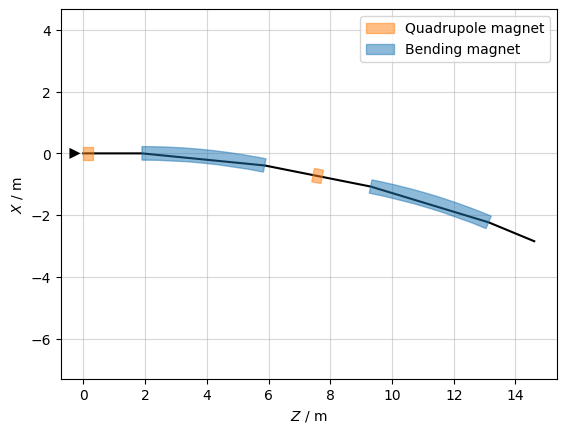

In [5]:
sv_cell = cell.survey()
sv_cell.plot()

### Set weak quadrupole strengths and calculate the optics

In [6]:
env['kqf'] = 0.10
env['kqd'] = -0.10

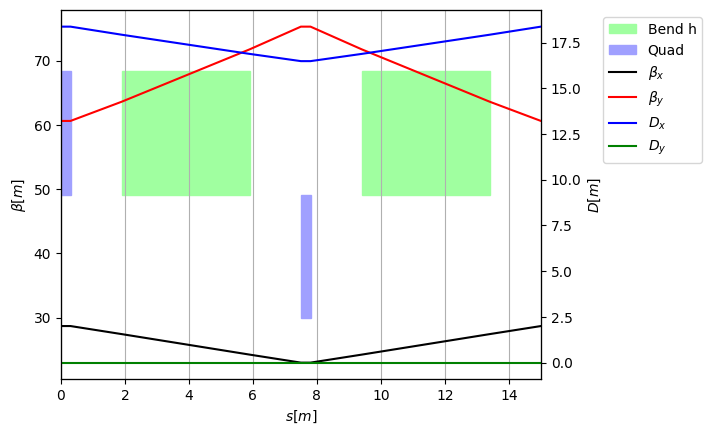

In [7]:
tw_cell = cell.twiss4d(chrom=False)
tw_cell.plot()

### Match the cell phase advances

For a periodic cell, `qx` and `qy` are the phase advances in units of $2\pi$. Targeting `91 / 360` and `92 / 360` therefore gives 91° and 92° per cell: close to 90°, with the full-ring tunes slightly shifted from integers.

In [8]:
opt_cell = cell.match(
    solve=False,
    method='4d',
    chrom=False,
    vary=[
        xt.Vary('kqf', limits=(0, 10), step=1e-3),
        xt.Vary('kqd', limits=(-10, 0), step=1e-3),
    ],
    targets=[
        xt.TargetSet(qx=91 / 360, qy=92 / 360, tol=1e-6),
    ],
)

In [9]:
opt_cell.target_status()

Target status:               
id state tag tol_met       residue   current_val    target_val description                             
0  ON    qx    False     -0.159998     0.0927799      0.252778 'qx', val=0.252778, tol=1e-06, weight=10
1  ON    qy    False     -0.220153     0.0354021      0.255556 'qy', val=0.255556, tol=1e-06, weight=10


In [10]:
opt_cell.run_jacobian(30)

Optimize - start penalty: 2.722                         



Optimize - end penalty:  1.0714e-09                            


In [11]:
opt_cell.target_status()
opt_cell.vary_status()

Target status:               
id state tag tol_met       residue   current_val    target_val description                             
0  ON    qx     True   6.51909e-11      0.252778      0.252778 'qx', val=0.252778, tol=1e-06, weight=10
1  ON    qy     True  -8.50249e-11      0.255556      0.255556 'qy', val=0.255556, tol=1e-06, weight=10
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kqf            0      0.612724          10           0.1         0.001             1
1  ON        OK  kqd          -10     -0.642094           0          -0.1         0.001             1


### Inspect the matched cell optics

Cell phase advances: 91.00° / 92.00°


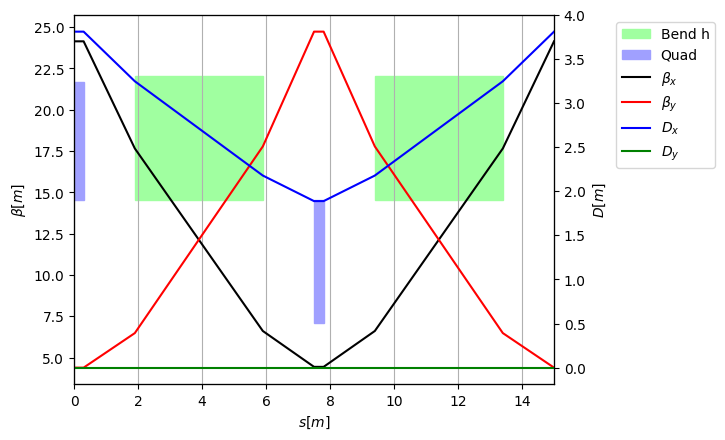

In [12]:
tw_cell = cell.twiss4d()
print(f'Cell phase advances: {360 * tw_cell.qx:.2f}° / {360 * tw_cell.qy:.2f}°')
tw_cell.plot()

### Assemble the ring

Repeat the cell 16 times, then give each magnet occurrence a unique name. The magnets remain linked to the same family variables.

In [13]:
ring = n_cells * cell
ring.replace_all_repeated_elements()

### Survey

In [14]:
sv = ring.survey()

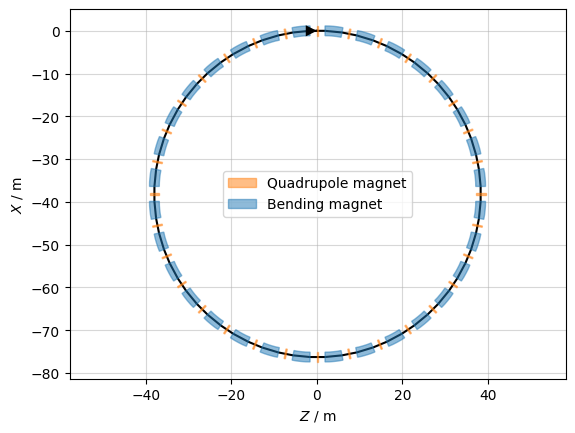

In [15]:
sv.plot()

### Full-ring optics

Ring tunes: 4.0444 / 4.0889


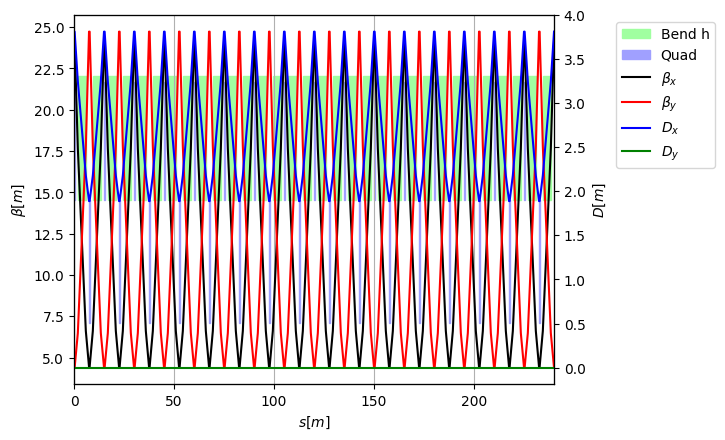

In [16]:
tw_ring = ring.twiss4d()
print(f'Ring tunes: {tw_ring.qx:.4f} / {tw_ring.qy:.4f}')
tw_ring.plot()